# 07 — Attention Module Localization: Sliding-Window Interchange

Same cross-language interchange design as 06, but at **module** granularity rather than head
granularity.  Instead of learning a differentiable mask, we do a brute-force sweep:
for each center layer `c` and a fixed window width `w`, we patch the full attention
module output (the vector written to the residual stream) at the **last token position**
from the C++ source prompt into the Python destination prompt, for all layers in
`[c - w//2, …, c + w//2]`.

**Three-role design:**

| Role | Predicate | Language | Purpose |
|------|-----------|----------|---------|
| **source** | `source_predicate` | C++ | provides the goal signal |
| **dest** | `destination_predicate` | Python | receives the patch |
| **target** | `source_predicate` | Python | what dest should become after patching |

**Score:** probability (or logit) of `pi.target_top_token` in the patched dest forward pass.

**Reading the plot:** a peak at layer `c` means the attention module at that layer
(when patched with C++ goal signal) most strongly shifts the Python dest toward the
target predicate.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import logging

import torch
import transformers
import numpy as np
from matplotlib import pyplot as plt
from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "4,5,6,7"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
##################################################################

console = Console(theme=Theme({"default": "white"}), highlight=False, width=120)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)
logger = logging.getLogger(__name__)

logger.info(f"{torch.__version__=}  {transformers.__version__=}")
logger.info(
    f"{torch.cuda.is_available()=}  "
    f"{torch.cuda.device_count()=}  "
    f"{torch.cuda.get_device_name()=}"
)

2026-03-19 12:43:35 __main__ INFO     torch.__version__='2.6.0+cu124'  transformers.__version__='5.3.0'
2026-03-19 12:43:35 __main__ INFO     torch.cuda.is_available()=True  torch.cuda.device_count()=4  torch.cuda.get_device_name()='NVIDIA A100-SXM4-80GB'


## Model init

In [3]:
from src.models import ModelandTokenizer

MODEL_KEY = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_KEY,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}  n_embd={mt.n_embd}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-03-19 12:43:38 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-19 12:43:38 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-03-19 12:43:38 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-03-19 12:43:38 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-19 12:43:38 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f07b659a890>
2026-03-19 12:43:38 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f07a7aa2720> server_hostname='huggingface.co' timeout=10
2026-03-19 12:43:38 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._b

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-19 12:43:54 httpcore.connection DEBUG    close.started
2026-03-19 12:43:54 httpcore.connection DEBUG    close.complete
2026-03-19 12:43:54 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-19 12:43:54 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f07a616ef50>
2026-03-19 12:43:54 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f07a7aa2720> server_hostname='huggingface.co' timeout=10
2026-03-19 12:43:54 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f07a60b61d0>
2026-03-19 12:43:54 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-19 12:43:54 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-19 12:43:54 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Load dataset

In [4]:
from src.goals.head_loc_data import HeadLocDataset

MODEL_SHORT = MODEL_KEY.split("/")[-1]
ds = HeadLocDataset.load(model_name=MODEL_SHORT)
pivot_instances = ds.pivot_instances  # list[tuple[PredicatePair, PivotInstance]]

print(f"Predicates    : {len(ds.samples)}")
print(f"Pairs total   : {len(ds.pairs)}")
print(f"Pivot instances: {len(pivot_instances)}")

2026-03-19 12:43:55 src.goals.head_loc_data INFO     Loaded 21 predicates, 110 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc/pairs/Qwen2.5-Coder-32B-Instruct.json
Predicates    : 21
Pairs total   : 110
Pivot instances: 1480


## Inspect one pivot instance

In [59]:
# Change INSTANCE_IDX to explore different pivot instances
INSTANCE_IDX = 0

# pair, pi = pivot_instances[INSTANCE_IDX]
pair, pi = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if pivot_idx.pivot_prefix.strip() == "s == s"
    and predicate_pair.source_predicate == "is_palindrome"
][0]

print("Pair:")
print(f"  destination_predicate : {pair.destination_predicate!r}  ← Python dest")
print(
    f"  source_predicate      : {pair.source_predicate!r}  ← C++ source / Python target"
)
print(f"  variable_type         : {pair.variable_type}")
print("\nPivot instance:")
print(f"  pivot_prefix     : {pi.pivot_prefix!r}")
print(f"  dest_top_token   : {pi.dest_top_token!r}   ← what dest predicts (unpatched)")
print(f"  target_top_token : {pi.target_top_token!r}  ← what we want after patching")

Pair:
  destination_predicate : 'is_lower'  ← Python dest
  source_predicate      : 'is_palindrome'  ← C++ source / Python target
  variable_type         : str

Pivot instance:
  pivot_prefix     : 's == s'
  dest_top_token   : '.lower'   ← what dest predicts (unpatched)
  target_top_token : '[::-'  ← what we want after patching


In [60]:
pair

PredicatePair(source_predicate='is_palindrome', destination_predicate='is_lower', variable_type='str', oracle_verified=True, kl_at_bare_return=0.0, top_token_diverges_at_bare_return=False, pivot_instances=[PivotInstance(pivot_prefix='s == s', dest_top_token='.lower', target_top_token='[::-'), PivotInstance(pivot_prefix='all', dest_top_token='(c', target_top_token='(s'), PivotInstance(pivot_prefix='s.lower() == s', dest_top_token='\n', target_top_token='[::-'), PivotInstance(pivot_prefix='not any', dest_top_token='(char', target_top_token='(s'), PivotInstance(pivot_prefix='bool(s == s', dest_top_token='.lower', target_top_token='[::-'), PivotInstance(pivot_prefix='not not s == s', dest_top_token='.lower', target_top_token='[::-'), PivotInstance(pivot_prefix='True and s == s', dest_top_token='.lower', target_top_token='[::-'), PivotInstance(pivot_prefix='False or s == s', dest_top_token='.lower', target_top_token='[::-'), PivotInstance(pivot_prefix='bool(all', dest_top_token='(c', target

In [61]:
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

src_prompt  = build_cpp_prompt(mt, ds.get_sample(pair.source_predicate), include_docstring=True)
dest_prompt = build_python_prompt(mt, ds.get_sample(pair.destination_predicate), pivot_prefix=pi.pivot_prefix, include_docstring=True)
targ_prompt = build_python_prompt(mt, ds.get_sample(pair.source_predicate), pivot_prefix=pi.pivot_prefix, include_docstring=True)

print("=== C++ source ===")
console.print(src_prompt)
print("\n=== Python destination ===")
console.print(dest_prompt)
print("\n=== Python target ===")
console.print(targ_prompt)

=== C++ source ===


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
// Return True if s reads the same forwards and backwards.
bool isPalindrome(string s) { return


=== Python destination ===


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_lower(s: str) -> bool:
    """Return True if all alphabetic characters in s are lowercase."""
    return s == s


=== Python target ===


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    """Return True if s reads the same forwards and backwards."""
    return s == s

## Single-instance window sweep

One call to `run_attn_window_sweep` runs:
1. Two unpatched forward passes (dest baseline + target baseline)
2. One forward pass through the C++ source to collect attn states at all layers
3. `n_layer` patched forward passes (one per window center)

Total: `n_layer + 3` forward passes.

In [64]:
from src.goals.head_loc_module import run_attn_window_sweep

WINDOW = 9 
METRIC = "logit"  # "prob" or "logit"

result = run_attn_window_sweep(
    mt, pair, pi, ds,
    window=WINDOW,
    metric=METRIC,
    include_docstring=True
)

peak_layer = max(result["sweep"], key=result["sweep"].get)
print(f"Target token   : {result['target_token']!r}  (id={result['target_token_id']})")
print(f"baseline_dest  : {result['baseline_dest']:.4f}  (lower bound — no patch)")
print(f"baseline_targ  : {result['baseline_targ']:.4f}  (upper bound — target prompt)")
print(f"Peak layer     : {peak_layer}")
print(f"Peak score     : {result['sweep'][peak_layer]:.4f}")

2026-03-19 14:11:53 src.goals.head_loc_module DEBUG    src_prompt:
"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
// Return True if s reads the same forwards and backwards.
bool isPalindrome(string s) { return "

2026-03-19 14:11:53 src.goals.head_loc_module DEBUG    dest_prompt:
"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_lower(s: str) -> bool:
    """Return True if all alphabetic characters in s are lowercase."""
    return s == s"

2026-03-19 14:11:53 src.goals.head_loc

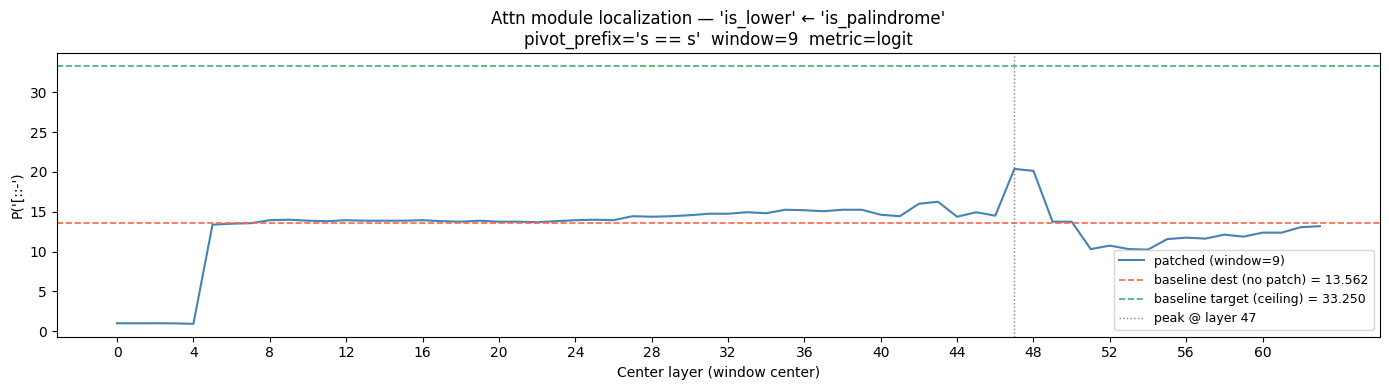

In [65]:
xs = sorted(result["sweep"].keys())
ys = [result["sweep"][x] for x in xs]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(xs, ys, lw=1.5, color="steelblue", label=f"patched (window={WINDOW})")
ax.axhline(
    result["baseline_dest"], ls="--", color="tomato", lw=1.2,
    label=f"baseline dest (no patch) = {result['baseline_dest']:.3f}",
)
ax.axhline(
    result["baseline_targ"], ls="--", color="mediumseagreen", lw=1.2,
    label=f"baseline target (ceiling) = {result['baseline_targ']:.3f}",
)
ax.axvline(peak_layer, ls=":", color="gray", lw=1.0, label=f"peak @ layer {peak_layer}")
ax.set_xlabel("Center layer (window center)")
ax.set_ylabel(f"P({result['target_token']!r})")
ax.set_title(
    f"Attn module localization — {pair.destination_predicate!r} ← {pair.source_predicate!r}\n"
    f"pivot_prefix={pi.pivot_prefix!r}  window={WINDOW}  metric={METRIC}"
)
ax.legend(fontsize=9)
ax.set_xticks(xs[::4])
plt.tight_layout()
plt.show()

### Score at each layer — table view

In [66]:
from rich.table import Table

table = Table(title=f"Window sweep scores  (window={WINDOW}  metric={METRIC})", highlight=False)
table.add_column("Layer", justify="right", style="cyan")
table.add_column("Score", justify="right", style="yellow")
table.add_column("Normalized", justify="right", style="green")
table.add_column("Bar")

lo, hi = result["baseline_dest"], result["baseline_targ"]
denom = (hi - lo) if hi > lo else 1.0
for layer in xs:
    score = result["sweep"][layer]
    normed = (score - lo) / denom
    bar = "█" * int(normed * 20)
    table.add_row(str(layer), f"{score:.4f}", f"{normed:.3f}", bar)

console.print(table)

     Window sweep scores  (window=9      
              metric=logit)              
┏━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┓
┃ Layer ┃   Score ┃ Normalized ┃ Bar    ┃
┡━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━┩
│     0 │  1.0078 │     -0.638 │        │
│     1 │  1.0000 │     -0.638 │        │
│     2 │  1.0078 │     -0.638 │        │
│     3 │  0.9922 │     -0.638 │        │
│     4 │  0.9336 │     -0.641 │        │
│     5 │ 13.3750 │     -0.010 │        │
│     6 │ 13.5000 │     -0.003 │        │
│     7 │ 13.5625 │      0.000 │        │
│     8 │ 13.9375 │      0.019 │        │
│     9 │ 14.0000 │      0.022 │        │
│    10 │ 13.8750 │      0.016 │        │
│    11 │ 13.8125 │      0.013 │        │
│    12 │ 13.9375 │      0.019 │        │
│    13 │ 13.8750 │      0.016 │        │
│    14 │ 13.8750 │      0.016 │        │
│    15 │ 13.8750 │      0.016 │        │
│    16 │ 13.9375 │      0.019 │        │
│    17 │ 13.8125 │      0.013 │        │
│    18 │ 13.7500 │      0.010 │        │
│    19 │ 13.8750 │      0.016 │        │
│    20 │ 13.7500 │      0.010 │        │
│    21 │ 13.7500 │      0.010 │        │
│    22 │ 13.6875 │      0.006 │        │
│    23 │ 13.8125 │      0.013 │        │
│    24 │ 13.9375 │      0.019 │        │
│    25 │ 14.0000 │      0.022 │        │
│    26 │ 13.9375 │      0.019 │        │
│    27 │ 14.4375 │      0.044 │        │
│    28 │ 14.3750 │      0.041 │        │
│    29 │ 14.4375 │      0.044 │        │
│    30 │ 14.5625 │      0.051 │ █      │
│    31 │ 14.7500 │      0.060 │ █      │
│    32 │ 14.7500 │      0.060 │ █      │
│    33 │ 14.9375 │      0.070 │ █      │
│    34 │ 14.8125 │      0.063 │ █      │
│    35 │ 15.2500 │      0.086 │ █      │
│    36 │ 15.1875 │      0.083 │ █      │
│    37 │ 15.0625 │      0.076 │ █      │
│    38 │ 15.2500 │      0.086 │ █      │
│    39 │ 15.2500 │      0.086 │ █      │
│    40 │ 14.6250 │      0.054 │ █      │
│    41 │ 14.4375 │      0.044 │        │
│    42 │ 16.0000 │      0.124 │ ██     │
│    43 │ 16.2500 │      0.137 │ ██     │
│    44 │ 14.3750 │      0.041 │        │
│    45 │ 14.9375 │      0.070 │ █      │
│    46 │ 14.5000 │      0.048 │        │
│    47 │ 20.3750 │      0.346 │ ██████ │
│    48 │ 20.1250 │      0.333 │ ██████ │
│    49 │ 13.7500 │      0.010 │        │
│    50 │ 13.7500 │      0.010 │        │
│    51 │ 10.3125 │     -0.165 │        │
│    52 │ 10.7500 │     -0.143 │        │
│    53 │ 10.3125 │     -0.165 │        │
│    54 │ 10.2500 │     -0.168 │        │
│    55 │ 11.5625 │     -0.102 │        │
│    56 │ 11.7500 │     -0.092 │        │
│    57 │ 11.6250 │     -0.098 │        │
│    58 │ 12.1250 │     -0.073 │        │
│    59 │ 11.8750 │     -0.086 │        │
│    60 │ 12.3750 │     -0.060 │        │
│    61 │ 12.3750 │     -0.060 │        │
│    62 │ 13.0625 │     -0.025 │        │
│    63 │ 13.1875 │     -0.019 │        │
└───────┴─────────┴────────────┴────────┘

## Aggregation over multiple pivot instances

Run the sweep over `N_INSTANCES` pivot instances and average the
**normalized** score (0 = dest baseline, 1 = target ceiling) across instances.
Instances where `baseline_targ <= baseline_dest` are discarded (no signal gap).

In [74]:
selected = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_lower"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected)

5

In [76]:
# Adjust N_INSTANCES and INSTANCE_STRIDE to control coverage vs. runtime.
# Each instance requires n_layer + 3 forward passes through the 32B model.
# N=10 → ~670 passes; budget ~10–20 min on 4×A100.
N_INSTANCES   = 10
INSTANCE_STRIDE = 1   # set > 1 to subsample the pivot list
AGG_WINDOW    = WINDOW
AGG_METRIC    = METRIC

# selected = pivot_instances[::INSTANCE_STRIDE][:N_INSTANCES]

selected = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_lower"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
print(f"Running sweep for {len(selected)} pivot instances (window={AGG_WINDOW})...")

all_results = []
for i, (pair_i, pi_i) in enumerate(selected):
    print(
        f"[{i+1:02d}/{len(selected)}] "
        f"{pair_i.destination_predicate!r} ← {pair_i.source_predicate!r}  "
        f"prefix={pi_i.pivot_prefix!r}"
    )
    r = run_attn_window_sweep(mt, pair_i, pi_i, ds, window=AGG_WINDOW, metric=AGG_METRIC)
    if r["baseline_targ"] > r["baseline_dest"]:
        all_results.append(r)
    else:
        print(f"  Skipped — no score gap (baseline_targ={r['baseline_targ']:.4f} "
              f"<= baseline_dest={r['baseline_dest']:.4f})")

print(f"\nUsable results: {len(all_results)} / {len(selected)}")

Running sweep for 5 pivot instances (window=9)...
[01/5] 'is_palindrome' ← 'is_lower'  prefix='s == s'
2026-03-19 14:23:17 src.goals.head_loc_module DEBUG    src_prompt:
"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
bool isLower(string s) { return "

2026-03-19 14:23:17 src.goals.head_loc_module DEBUG    dest_prompt:
"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return s == s"

2026-03-19 14:23:17 src.goals.head_loc_module DEBUG    targ_promp

2026-03-19 14:23:18 src.goals.head_loc_module INFO     [is_palindrome ← is_lower] prefix='s == s'  target='.lower'  baseline_dest=16.2500  baseline_targ=35.7500
2026-03-19 14:23:18 src.goals.head_loc_module DEBUG      baseline src  (C++) top5: [ "' all'" (20.25), "'1'" (19.62), "' s'" (19.00), "'0'" (19.00), "' std'" (17.75) ]
2026-03-19 14:23:18 src.goals.head_loc_module DEBUG      baseline dest (Py)  top5: [ "'[::-'" (34.25), "'['" (20.00), "'[:'" (19.38), "'[-'" (19.25), "'.reverse'" (17.88) ]
2026-03-19 14:23:18 src.goals.head_loc_module DEBUG      baseline targ (Py)  top5: [ "'.lower'" (35.75), "'.toLowerCase'" (21.62), "' lower'" (20.50), "'_lower'" (19.88), "'lower'" (18.50) ]
2026-03-19 14:23:18 src.goals.head_loc_module DEBUG      window center=  0  score=4.1250  top5: [ "' s'" (18.88), "" ''."" (15.56), "' #'" (14.12), "'s'" (13.44), "'ｓ'" (12.81) ]
2026-03-19 14:23:18 src.goals.head_loc_module DEBUG      window center=  1  score=4.1562  top5: [ "' s'" (18.88), "" ''."" (15.5

In [77]:
# Normalize each sweep to [0, 1] and compute per-layer mean ± std

n_layer = mt.n_layer
norm_matrix = []  # (n_usable, n_layer)

for r in all_results:
    lo_r, hi_r = r["baseline_dest"], r["baseline_targ"]
    normed = np.array([
        (r["sweep"][c] - lo_r) / (hi_r - lo_r)
        for c in range(n_layer)
    ])
    norm_matrix.append(normed)

norm_matrix = np.array(norm_matrix)  # (n_usable, n_layer)
mean_score = norm_matrix.mean(axis=0)
std_score  = norm_matrix.std(axis=0)

peak_agg = int(np.argmax(mean_score))
print(f"Aggregate peak layer: {peak_agg}  (mean normalized score: {mean_score[peak_agg]:.3f})")
print(f"Top 5 layers: {np.argsort(mean_score)[::-1][:5].tolist()}")

Aggregate peak layer: 50  (mean normalized score: 0.361)
Top 5 layers: [50, 52, 51, 45, 53]


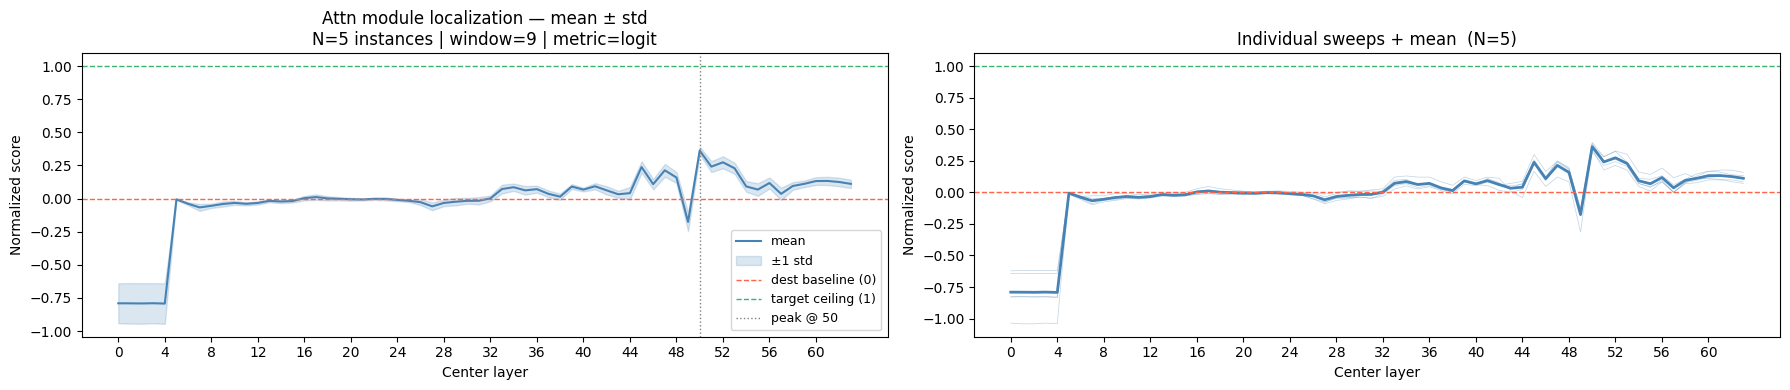

In [78]:
xs_agg = np.arange(n_layer)

fig, axes = plt.subplots(1, 2, figsize=(18, 4))

# ── Left: mean ± std ─────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(xs_agg, mean_score, lw=1.5, color="steelblue", label="mean")
ax.fill_between(
    xs_agg,
    mean_score - std_score,
    mean_score + std_score,
    alpha=0.20, color="steelblue", label="±1 std",
)
ax.axhline(0.0, ls="--", color="tomato",        lw=1.0, label="dest baseline (0)")
ax.axhline(1.0, ls="--", color="mediumseagreen", lw=1.0, label="target ceiling (1)")
ax.axvline(peak_agg, ls=":", color="gray", lw=1.0, label=f"peak @ {peak_agg}")
ax.set_xlabel("Center layer")
ax.set_ylabel("Normalized score")
ax.set_title(
    f"Attn module localization — mean ± std\n"
    f"N={len(all_results)} instances | window={AGG_WINDOW} | metric={AGG_METRIC}"
)
ax.legend(fontsize=9)
ax.set_xticks(xs_agg[::4])

# ── Right: all individual sweeps (faint) + mean ───────────────────────────────
ax2 = axes[1]
for row in norm_matrix:
    ax2.plot(xs_agg, row, lw=0.5, alpha=0.35, color="steelblue")
ax2.plot(xs_agg, mean_score, lw=2.0, color="steelblue", label="mean")
ax2.axhline(0.0, ls="--", color="tomato",        lw=1.0)
ax2.axhline(1.0, ls="--", color="mediumseagreen", lw=1.0)
ax2.set_xlabel("Center layer")
ax2.set_ylabel("Normalized score")
ax2.set_title(f"Individual sweeps + mean  (N={len(all_results)})")
ax2.set_xticks(xs_agg[::4])

plt.tight_layout()
plt.show()

In [80]:
mt.n_layer

64

In [79]:
# Top-10 layers by mean normalized score
top_layers = np.argsort(mean_score)[::-1][:10]
print("Top 10 layers by mean normalized score:")
for rank, l in enumerate(top_layers, 1):
    bar = "█" * int(mean_score[l] * 30)
    print(f"  {rank:2d}. layer {l:3d}: {mean_score[l]:.4f} ± {std_score[l]:.4f}  {bar}")

Top 10 layers by mean normalized score:
   1. layer  50: 0.3614 ± 0.0282  ██████████
   2. layer  52: 0.2732 ± 0.0452  ████████
   3. layer  51: 0.2406 ± 0.0412  ███████
   4. layer  45: 0.2376 ± 0.0431  ███████
   5. layer  53: 0.2281 ± 0.0419  ██████
   6. layer  47: 0.2130 ± 0.0481  ██████
   7. layer  48: 0.1583 ± 0.0415  ████
   8. layer  61: 0.1326 ± 0.0308  ███
   9. layer  60: 0.1319 ± 0.0293  ███
  10. layer  62: 0.1245 ± 0.0323  ███


## Window size comparison (optional)

Run sweeps with multiple window sizes on a single instance to see how
resolution affects the localization picture.

In [ ]:
WINDOWS_TO_COMPARE = [1, 3, 5, 11]

# Reuse INSTANCE_IDX from above
pair_cmp, pi_cmp = pivot_instances[INSTANCE_IDX]

fig, ax = plt.subplots(figsize=(14, 4))
colors = ["steelblue", "darkorange", "mediumseagreen", "mediumpurple"]

r_ref = None
for win, col in zip(WINDOWS_TO_COMPARE, colors):
    r_win = run_attn_window_sweep(mt, pair_cmp, pi_cmp, ds, window=win, metric=METRIC)
    if r_ref is None:
        r_ref = r_win
    xs_w = sorted(r_win["sweep"].keys())
    ys_w = [r_win["sweep"][x] for x in xs_w]
    ax.plot(xs_w, ys_w, lw=1.3, color=col, label=f"window={win}")

ax.axhline(r_ref["baseline_dest"], ls="--", color="tomato",        lw=1.0, label="baseline dest")
ax.axhline(r_ref["baseline_targ"], ls="--", color="mediumseagreen", lw=1.0, label="baseline targ")
ax.set_xlabel("Center layer")
ax.set_ylabel(f"P({r_ref['target_token']!r})")
ax.set_title(
    f"Window size comparison — {pair_cmp.destination_predicate!r} ← {pair_cmp.source_predicate!r}"
)
ax.legend(fontsize=9)
ax.set_xticks(sorted(r_ref["sweep"].keys())[::4])
plt.tight_layout()
plt.show()

## Boundary sweep: upto-L and from-L

Instead of a sliding window, patch a **growing prefix** or **shrinking suffix** of layers:

- **`mode="upto"`** — at boundary `l`, patch layers `[0 … l]`.  
  Score starts low (few layers patched) and rises as more context is transferred.  
  The layer where it *plateaus* is where the model has received enough goal signal.

- **`mode="from"`** — at boundary `l`, patch layers `[l … n_layer-1]`.  
  Score starts high (all layers patched) and drops as we move `l` later.  
  The layer where it *drops sharply* is where the processed signal first becomes critical.

Together, the two curves bracket the critical layer range.

2026-03-19 13:13:37 src.goals.head_loc_module DEBUG    src_prompt:
"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
// Return True if s reads the same forwards and backwards.
bool isPalindrome(string s) { return "

2026-03-19 13:13:37 src.goals.head_loc_module DEBUG    dest_prompt:
"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_lower(s: str) -> bool:
    """Return True if all alphabetic characters in s are lowercase."""
    return s == s"

2026-03-19 13:13:37 src.goals.head_loc

2026-03-19 13:13:38 src.goals.head_loc_module INFO     [is_lower ← is_palindrome] prefix='s == s'  target='[::-'  baseline_dest=13.5625  baseline_targ=33.2500
2026-03-19 13:13:38 src.goals.head_loc_module DEBUG      baseline src  (C++) top5: "'0'"[15] (p=0.965, logit=22.375)  "'1'"[16] (p=0.026, logit=18.750)  "' s'"[274] (p=0.006, logit=17.250)  "' }\n'"[456] (p=0.001, logit=15.688)  "' equal'"[6144] (p=0.001, logit=15.000)
2026-03-19 13:13:38 src.goals.head_loc_module DEBUG      baseline dest (Py)  top5: "'.lower'"[18073] (p=1.000, logit=36.250)  "'.toLowerCase'"[16924] (p=0.000, logit=21.250)  "' lower'"[4722] (p=0.000, logit=20.625)  "'lower'"[14772] (p=0.000, logit=19.500)  "'_lower'"[30425] (p=0.000, logit=19.375)
2026-03-19 13:13:38 src.goals.head_loc_module DEBUG      baseline targ (Py)  top5: "'[::-'"[62154] (p=1.000, logit=33.250)  "'['"[58] (p=0.000, logit=19.500)  "'[-'"[7609] (p=0.000, logit=19.125)  "'[:'"[3447] (p=0.000, logit=18.625)  "'.reverse'"[32081] (p=0.000, logit

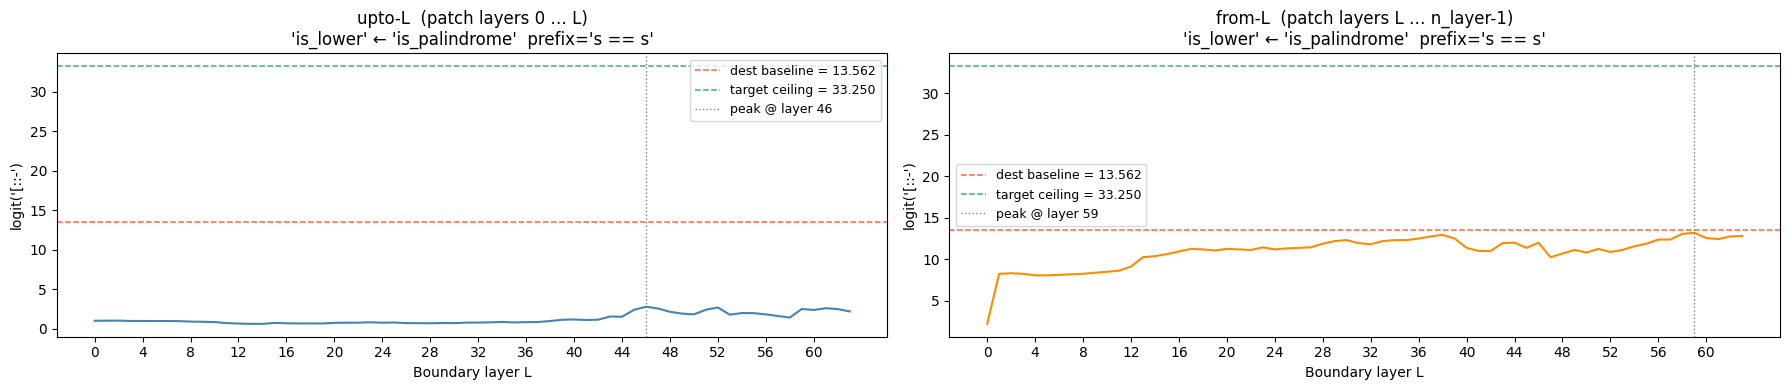

In [44]:
from src.goals.head_loc_module import run_attn_boundary_sweep

# Reuse the same pair/pi from the single-instance section above
BOUNDARY_METRIC = METRIC  # inherit from window-sweep cells

result_upto = run_attn_boundary_sweep(
    mt, pair, pi, ds, mode="upto", metric=BOUNDARY_METRIC, include_docstring=True
)
result_from = run_attn_boundary_sweep(
    mt, pair, pi, ds, mode="from", metric=BOUNDARY_METRIC, include_docstring=True
)

xs_b = list(range(mt.n_layer))

fig, axes = plt.subplots(1, 2, figsize=(18, 4), sharey=False)

for ax, res, title_mode, color in [
    (axes[0], result_upto, "upto-L  (patch layers 0 … L)", "steelblue"),
    (axes[1], result_from, "from-L  (patch layers L … n_layer-1)", "darkorange"),
]:
    ys = [res["sweep"][l] for l in xs_b]
    ax.plot(xs_b, ys, lw=1.5, color=color)
    ax.axhline(
        res["baseline_dest"],
        ls="--",
        color="tomato",
        lw=1.1,
        label=f"dest baseline = {res['baseline_dest']:.3f}",
    )
    ax.axhline(
        res["baseline_targ"],
        ls="--",
        color="mediumseagreen",
        lw=1.1,
        label=f"target ceiling = {res['baseline_targ']:.3f}",
    )
    peak_b = max(res["sweep"], key=res["sweep"].get)
    ax.axvline(peak_b, ls=":", color="gray", lw=1.0, label=f"peak @ layer {peak_b}")
    ax.set_xlabel("Boundary layer L")
    ax.set_ylabel(f"{BOUNDARY_METRIC}({res['target_token']!r})")
    ax.set_title(
        f"{title_mode}\n"
        f"{pair.destination_predicate!r} ← {pair.source_predicate!r}  "
        f"prefix={pi.pivot_prefix!r}"
    )
    ax.legend(fontsize=9)
    ax.set_xticks(xs_b[::4])

plt.tight_layout()
plt.show()

### Boundary sweep — table view

In [46]:
from rich.table import Table

def _boundary_table(res, title):
    lo, hi = res["baseline_dest"], res["baseline_targ"]
    denom = (hi - lo) if hi > lo else 1.0
    table = Table(title=title, highlight=False)
    table.add_column("L",        justify="right",  style="cyan")
    table.add_column("N patched", justify="right", style="dim")
    table.add_column("Score",    justify="right",  style="yellow")
    table.add_column("Normalized", justify="right", style="green")
    table.add_column("Bar")
    mode = res["mode"]
    n = mt.n_layer
    for l in range(n):
        n_patched = (l + 1) if mode == "upto" else (n - l)
        score  = res["sweep"][l]
        normed = (score - lo) / denom
        bar    = "█" * max(0, int(normed * 20))
        table.add_row(str(l), str(n_patched), f"{score:.4f}", f"{normed:.3f}", bar)
    return table

console.print(_boundary_table(result_upto, f"upto-L sweep  ({BOUNDARY_METRIC})"))
console.print()
console.print(_boundary_table(result_from, f"from-L sweep  ({BOUNDARY_METRIC})"))

            upto-L sweep  (logit)             
┏━━━━┳━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━┓
┃  L ┃ N patched ┃  Score ┃ Normalized ┃ Bar ┃
┡━━━━╇━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━┩
│  0 │         1 │ 1.0391 │     -0.636 │     │
│  1 │         2 │ 1.0469 │     -0.636 │     │
│  2 │         3 │ 1.0547 │     -0.635 │     │
│  3 │         4 │ 1.0156 │     -0.637 │     │
│  4 │         5 │ 1.0078 │     -0.638 │     │
│  5 │         6 │ 1.0000 │     -0.638 │     │
│  6 │         7 │ 1.0078 │     -0.638 │     │
│  7 │         8 │ 0.9922 │     -0.638 │     │
│  8 │         9 │ 0.9336 │     -0.641 │     │
│  9 │        10 │ 0.9102 │     -0.643 │     │
│ 10 │        11 │ 0.8750 │     -0.644 │     │
│ 11 │        12 │ 0.7461 │     -0.651 │     │
│ 12 │        13 │ 0.6875 │     -0.654 │     │
│ 13 │        14 │ 0.6484 │     -0.656 │     │
│ 14 │        15 │ 0.6484 │     -0.656 │     │
│ 15 │        16 │ 0.7578 │     -0.650 │     │
│ 16 │        17 │ 0.7227 │     -0.652 │     │
│ 17 │        18 │ 0.6992 │     -0.653 │     │
│ 18 │        19 │ 0.7031 │     -0.653 │     │
│ 19 │        20 │ 0.6953 │     -0.654 │     │
│ 20 │        21 │ 0.7734 │     -0.650 │     │
│ 21 │        22 │ 0.7930 │     -0.649 │     │
│ 22 │        23 │ 0.7969 │     -0.648 │     │
│ 23 │        24 │ 0.8438 │     -0.646 │     │
│ 24 │        25 │ 0.7930 │     -0.649 │     │
│ 25 │        26 │ 0.8203 │     -0.647 │     │
│ 26 │        27 │ 0.7383 │     -0.651 │     │
│ 27 │        28 │ 0.7344 │     -0.652 │     │
│ 28 │        29 │ 0.7227 │     -0.652 │     │
│ 29 │        30 │ 0.7500 │     -0.651 │     │
│ 30 │        31 │ 0.7344 │     -0.652 │     │
│ 31 │        32 │ 0.8047 │     -0.648 │     │
│ 32 │        33 │ 0.8086 │     -0.648 │     │
│ 33 │        34 │ 0.8398 │     -0.646 │     │
│ 34 │        35 │ 0.8867 │     -0.644 │     │
│ 35 │        36 │ 0.8281 │     -0.647 │     │
│ 36 │        37 │ 0.8633 │     -0.645 │     │
│ 37 │        38 │ 0.8789 │     -0.644 │     │
│ 38 │        39 │ 1.0078 │     -0.638 │     │
│ 39 │        40 │ 1.1641 │     -0.630 │     │
│ 40 │        41 │ 1.2031 │     -0.628 │     │
│ 41 │        42 │ 1.1328 │     -0.631 │     │
│ 42 │        43 │ 1.1719 │     -0.629 │     │
│ 43 │        44 │ 1.5781 │     -0.609 │     │
│ 44 │        45 │ 1.5469 │     -0.610 │     │
│ 45 │        46 │ 2.4219 │     -0.566 │     │
│ 46 │        47 │ 2.8125 │     -0.546 │     │
│ 47 │        48 │ 2.5938 │     -0.557 │     │
│ 48 │        49 │ 2.1719 │     -0.579 │     │
│ 49 │        50 │ 1.9453 │     -0.590 │     │
│ 50 │        51 │ 1.8438 │     -0.595 │     │
│ 51 │        52 │ 2.4375 │     -0.565 │     │
│ 52 │        53 │ 2.7188 │     -0.551 │     │
│ 53 │        54 │ 1.8047 │     -0.597 │     │
│ 54 │        55 │ 2.0156 │     -0.587 │     │
│ 55 │        56 │ 2.0000 │     -0.587 │     │
│ 56 │        57 │ 1.8516 │     -0.595 │     │
│ 57 │        58 │ 1.6406 │     -0.606 │     │
│ 58 │        59 │ 1.4453 │     -0.615 │     │
│ 59 │        60 │ 2.5312 │     -0.560 │     │
│ 60 │        61 │ 2.4062 │     -0.567 │     │
│ 61 │        62 │ 2.6250 │     -0.556 │     │
│ 62 │        63 │ 2.5156 │     -0.561 │     │
│ 63 │        64 │ 2.2188 │     -0.576 │     │
└────┴───────────┴────────┴────────────┴─────┘

             from-L sweep  (logit)             
┏━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━┓
┃  L ┃ N patched ┃   Score ┃ Normalized ┃ Bar ┃
┡━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━┩
│  0 │        64 │  2.2188 │     -0.576 │     │
│  1 │        63 │  8.2500 │     -0.270 │     │
│  2 │        62 │  8.3125 │     -0.267 │     │
│  3 │        61 │  8.2500 │     -0.270 │     │
│  4 │        60 │  8.0625 │     -0.279 │     │
│  5 │        59 │  8.0625 │     -0.279 │     │
│  6 │        58 │  8.1250 │     -0.276 │     │
│  7 │        57 │  8.1875 │     -0.273 │     │
│  8 │        56 │  8.2500 │     -0.270 │     │
│  9 │        55 │  8.3750 │     -0.263 │     │
│ 10 │        54 │  8.5000 │     -0.257 │     │
│ 11 │        53 │  8.6250 │     -0.251 │     │
│ 12 │        52 │  9.1250 │     -0.225 │     │
│ 13 │        51 │ 10.2500 │     -0.168 │     │
│ 14 │        50 │ 10.3750 │     -0.162 │     │
│ 15 │        49 │ 10.6250 │     -0.149 │     │
│ 16 │        48 │ 10.9375 │     -0.133 │     │
│ 17 │        47 │ 11.2500 │     -0.117 │     │
│ 18 │        46 │ 11.1875 │     -0.121 │     │
│ 19 │        45 │ 11.0625 │     -0.127 │     │
│ 20 │        44 │ 11.2500 │     -0.117 │     │
│ 21 │        43 │ 11.1875 │     -0.121 │     │
│ 22 │        42 │ 11.1250 │     -0.124 │     │
│ 23 │        41 │ 11.4375 │     -0.108 │     │
│ 24 │        40 │ 11.1875 │     -0.121 │     │
│ 25 │        39 │ 11.3125 │     -0.114 │     │
│ 26 │        38 │ 11.3750 │     -0.111 │     │
│ 27 │        37 │ 11.4375 │     -0.108 │     │
│ 28 │        36 │ 11.8750 │     -0.086 │     │
│ 29 │        35 │ 12.1875 │     -0.070 │     │
│ 30 │        34 │ 12.3125 │     -0.063 │     │
│ 31 │        33 │ 11.9375 │     -0.083 │     │
│ 32 │        32 │ 11.8125 │     -0.089 │     │
│ 33 │        31 │ 12.1875 │     -0.070 │     │
│ 34 │        30 │ 12.3125 │     -0.063 │     │
│ 35 │        29 │ 12.3125 │     -0.063 │     │
│ 36 │        28 │ 12.5000 │     -0.054 │     │
│ 37 │        27 │ 12.7500 │     -0.041 │     │
│ 38 │        26 │ 12.9375 │     -0.032 │     │
│ 39 │        25 │ 12.5000 │     -0.054 │     │
│ 40 │        24 │ 11.3750 │     -0.111 │     │
│ 41 │        23 │ 11.0000 │     -0.130 │     │
│ 42 │        22 │ 11.0000 │     -0.130 │     │
│ 43 │        21 │ 11.9375 │     -0.083 │     │
│ 44 │        20 │ 12.0000 │     -0.079 │     │
│ 45 │        19 │ 11.3750 │     -0.111 │     │
│ 46 │        18 │ 12.0000 │     -0.079 │     │
│ 47 │        17 │ 10.2500 │     -0.168 │     │
│ 48 │        16 │ 10.6875 │     -0.146 │     │
│ 49 │        15 │ 11.1250 │     -0.124 │     │
│ 50 │        14 │ 10.8125 │     -0.140 │     │
│ 51 │        13 │ 11.2500 │     -0.117 │     │
│ 52 │        12 │ 10.8750 │     -0.137 │     │
│ 53 │        11 │ 11.1250 │     -0.124 │     │
│ 54 │        10 │ 11.5625 │     -0.102 │     │
│ 55 │         9 │ 11.8750 │     -0.086 │     │
│ 56 │         8 │ 12.3750 │     -0.060 │     │
│ 57 │         7 │ 12.3750 │     -0.060 │     │
│ 58 │         6 │ 13.0625 │     -0.025 │     │
│ 59 │         5 │ 13.1875 │     -0.019 │     │
│ 60 │         4 │ 12.5625 │     -0.051 │     │
│ 61 │         3 │ 12.4375 │     -0.057 │     │
│ 62 │         2 │ 12.7500 │     -0.041 │     │
│ 63 │         1 │ 12.8125 │     -0.038 │     │
└────┴───────────┴─────────┴────────────┴─────┘

### Boundary sweep — aggregation over multiple instances

In [23]:
# Reuse the same selected instances from the window aggregation cell above.
# Each instance runs 2 × (n_layer + 3) passes (one upto sweep + one from sweep).

print(f"Running boundary sweeps for {len(selected)} pivot instances...")

upto_results, from_results = [], []
for i, (pair_i, pi_i) in enumerate(selected):
    label = (
        f"[{i+1:02d}/{len(selected)}] "
        f"{pair_i.destination_predicate!r} ← {pair_i.source_predicate!r}  "
        f"prefix={pi_i.pivot_prefix!r}"
    )
    print(label)
    r_up = run_attn_boundary_sweep(mt, pair_i, pi_i, ds, mode="upto", metric=AGG_METRIC)
    r_fr = run_attn_boundary_sweep(mt, pair_i, pi_i, ds, mode="from", metric=AGG_METRIC)
    # Only keep instances with a meaningful score gap
    if r_up["baseline_targ"] > r_up["baseline_dest"]:
        upto_results.append(r_up)
        from_results.append(r_fr)
    else:
        print(f"  Skipped — no score gap")

print(f"\nUsable results: {len(upto_results)} / {len(selected)}")

def _norm_matrix(results):
    mat = []
    for r in results:
        lo, hi = r["baseline_dest"], r["baseline_targ"]
        denom = hi - lo
        mat.append(np.array([(r["sweep"][l] - lo) / denom for l in range(mt.n_layer)]))
    return np.array(mat)

upto_mat = _norm_matrix(upto_results)
from_mat = _norm_matrix(from_results)

upto_mean, upto_std = upto_mat.mean(0), upto_mat.std(0)
from_mean, from_std = from_mat.mean(0), from_mat.std(0)

peak_upto = int(np.argmax(upto_mean))
peak_from = int(np.argmax(from_mean))
print(f"upto peak: layer {peak_upto}  (mean norm={upto_mean[peak_upto]:.3f})")
print(f"from peak: layer {peak_from}  (mean norm={from_mean[peak_from]:.3f}")

NameError: name 'selected' is not defined

In [ ]:
xs_agg = np.arange(mt.n_layer)

fig, axes = plt.subplots(1, 2, figsize=(18, 4))

for ax, mean, std, mat, mode_label, color, peak in [
    (axes[0], upto_mean, upto_std, upto_mat, "upto-L", "steelblue",   peak_upto),
    (axes[1], from_mean, from_std, from_mat, "from-L", "darkorange",  peak_from),
]:
    for row in mat:
        ax.plot(xs_agg, row, lw=0.5, alpha=0.3, color=color)
    ax.plot(xs_agg, mean, lw=2.0, color=color, label="mean")
    ax.fill_between(xs_agg, mean - std, mean + std, alpha=0.18, color=color, label="±1 std")
    ax.axhline(0.0, ls="--", color="tomato",        lw=1.0, label="dest baseline (0)")
    ax.axhline(1.0, ls="--", color="mediumseagreen", lw=1.0, label="target ceiling (1)")
    ax.axvline(peak, ls=":", color="gray", lw=1.0, label=f"peak @ {peak}")
    ax.set_xlabel("Boundary layer L")
    ax.set_ylabel("Normalized score")
    ax.set_title(
        f"Boundary sweep — {mode_label}  (mean ± std)\n"
        f"N={len(upto_results)} instances | metric={AGG_METRIC}"
    )
    ax.legend(fontsize=9)
    ax.set_xticks(xs_agg[::4])

plt.tight_layout()
plt.show()

### All three sweeps overlaid (single instance)

Overlay window, upto, and from sweeps on a single plot to visually cross-check
where the curves agree on the critical layer range.

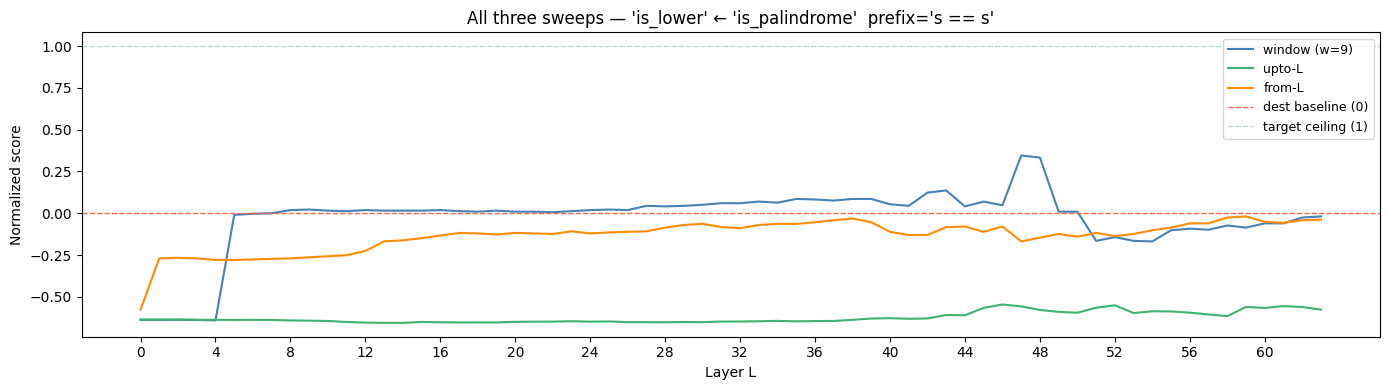

In [47]:
# Uses result (window), result_upto, result_from — all from the same pair/pi above.
# Normalise each curve to [0, 1] using its own baselines.

def _norm_sweep(res):
    lo, hi = res["baseline_dest"], res["baseline_targ"]
    denom = (hi - lo) if hi > lo else 1.0
    return np.array([(res["sweep"][l] - lo) / denom for l in range(mt.n_layer)])

xs = np.arange(mt.n_layer)
norm_window = _norm_sweep(result)
norm_upto   = _norm_sweep(result_upto)
norm_from   = _norm_sweep(result_from)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(xs, norm_window, lw=1.5, color="steelblue",  label=f"window (w={WINDOW})")
ax.plot(xs, norm_upto,   lw=1.5, color="mediumseagreen", label="upto-L")
ax.plot(xs, norm_from,   lw=1.5, color="darkorange",  label="from-L")
ax.axhline(0.0, ls="--", color="tomato",        lw=1.0, label="dest baseline (0)")
ax.axhline(1.0, ls="--", color="mediumseagreen", lw=1.0, alpha=0.4, label="target ceiling (1)")
ax.set_xlabel("Layer L")
ax.set_ylabel("Normalized score")
ax.set_title(
    f"All three sweeps — {pair.destination_predicate!r} ← {pair.source_predicate!r}  "
    f"prefix={pi.pivot_prefix!r}"
)
ax.legend(fontsize=9)
ax.set_xticks(xs[::4])
plt.tight_layout()
plt.show()